
TABLE S10
    Strategy  Objective  Deviation K=300 from K=5000 (%)  Spread K=100 (%)  Spread K=300 (%)
      Normal Irrigation                            0.014             0.176             0.102
      Normal      Yield                            0.057             1.297             0.299
     Extreme Irrigation                            0.056             0.876             0.397
     Extreme      Yield                            0.022             1.171             0.759
Very extreme Irrigation                            0.040             0.830             0.328
Very extreme      Yield                            0.066             1.864             0.726

Smallest K meeting the 1% criterion: 300
Maximum spread at K=300: 0.759%
Maximum deviation at K=300: 0.066%


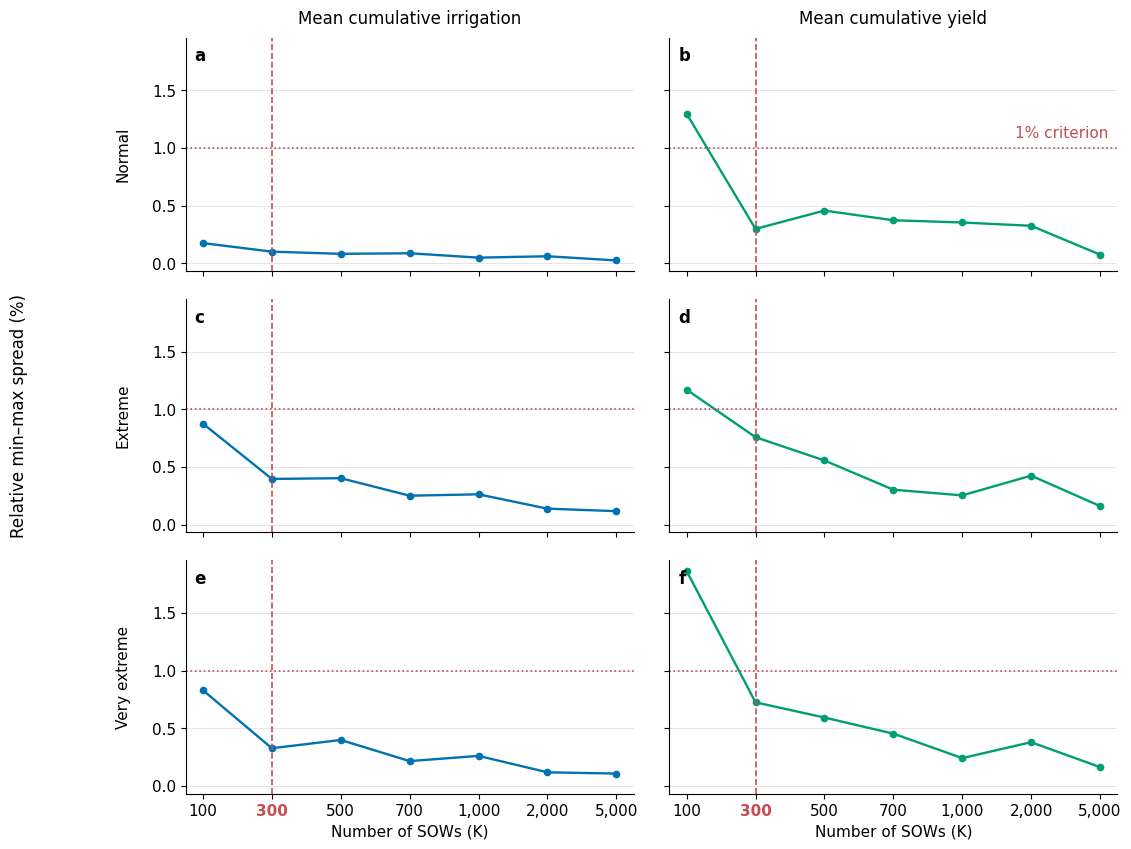

In [1]:
# Convergence Analysis of Mean Irrigation and Yield (K = 100–5,000)

# Table S10 and  Figure S11

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

input_folder = Path("Output_convergence_Normal_Extreme_VeryExtreme_K5000_10Seeds")
K_OPT = 300
CRITERION = 1.0
summary_files = sorted(input_folder.glob("convergence_summary_*.csv"))
if not summary_files:
    raise FileNotFoundError("No convergence summary file found.")
df = pd.read_csv(summary_files[0])
df["irr_spread_pct"] = (df["irr_max"] - df["irr_min"]) / df["irr_mean"].abs() * 100
df["yld_spread_pct"] = (df["yld_max"] - df["yld_min"]) / df["yld_mean"].abs() * 100
df["irr_dev_pct"] = abs(df["irr_mean"] - df["irr_ref"]) / abs(df["irr_ref"]) * 100
df["yld_dev_pct"] = abs(df["yld_mean"] - df["yld_ref"]) / abs(df["yld_ref"]) * 100

df["both_below_1pct"] = (
    (df["irr_spread_pct"] < CRITERION) &
    (df["yld_spread_pct"] < CRITERION)
)
passing = df.groupby("K")["both_below_1pct"].all()
passing_K = passing[passing].index.tolist()
smallest_K_all_pass = min(passing_K) if passing_K else None
strategies = {
    "Normal": "normal",
    "Extreme": "extreme",
    "Very extreme": "very_extreme"
}
# Table S10
rows = []
for label, code in strategies.items():
    d = df[df["strategy"] == code]
    r100 = d.loc[d["K"] == 100].iloc[0]
    r300 = d.loc[d["K"] == K_OPT].iloc[0]
    for objective, prefix in [("Irrigation", "irr"), ("Yield", "yld")]:
        rows.append({
            "Strategy": label,
            "Objective": objective,
            "Deviation K=300 from K=5000 (%)": r300[f"{prefix}_dev_pct"],
            "Spread K=100 (%)": r100[f"{prefix}_spread_pct"],
            "Spread K=300 (%)": r300[f"{prefix}_spread_pct"]
        })
table = pd.DataFrame(rows)
print("\nTABLE S10")
print(table.round(3).to_string(index=False))
print(f"\nSmallest K meeting the 1% criterion: {smallest_K_all_pass}")
k300 = df[df["K"] == K_OPT]
max_spread = max(k300["irr_spread_pct"].max(), k300["yld_spread_pct"].max())
max_deviation = max(k300["irr_dev_pct"].max(), k300["yld_dev_pct"].max())
print(f"Maximum spread at K=300: {max_spread:.3f}%")
print(f"Maximum deviation at K=300: {max_deviation:.3f}%")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8,
})
all_K = sorted(df["K"].unique())
x_positions = np.arange(len(all_K))
k_to_position = {k: i for i, k in enumerate(all_K)}
k_opt_position = k_to_position[K_OPT]
fig, axes = plt.subplots(
    3, 2,
    figsize=(11.5, 9),
    sharex=True,
    sharey=True,
    constrained_layout=False
)
fig.subplots_adjust(
    left=0.17,
    right=0.98,
    top=0.94,
    bottom=0.10,
    hspace=0.12,
    wspace=0.08
)
panel_labels = ["a", "b", "c", "d", "e", "f"]

colors = {
    "Irrigation": "#0072B2",
    "Yield": "#009E73"
}
for i, (label, code) in enumerate(strategies.items()):
    d = df[df["strategy"] == code].sort_values("K")
    x = d["K"].map(k_to_position).to_numpy()

    for j, (objective, column) in enumerate([
        ("Irrigation", "irr_spread_pct"),
        ("Yield", "yld_spread_pct")
    ]):
        ax = axes[i, j]
        ax.plot(
            x,
            d[column],
            color=colors[objective],
            marker="o",
            markersize=4.5,
            linewidth=1.7
        )
        ax.axhline(
            CRITERION,
            color="#C44E52",
            linestyle=":",
            linewidth=1.2
        )
        ax.axvline(
            k_opt_position,
            color="#C44E52",
            linestyle="--",
            linewidth=1.2
        )
        ax.text(
            0.02, 0.96,
            panel_labels[i * 2 + j],
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            ha="left",
            va="top"
        )
        ax.grid(axis="y", color="0.88", linewidth=0.6)
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(
            direction="out",
            length=3.5,
            labelsize=11
        )
        ax.set_xticks(x_positions)
        ax.set_xticklabels([f"{k:,}" for k in all_K])
        ax.set_xlim(-0.25, len(all_K) - 0.75)
        ax.minorticks_off()
axes[0, 0].set_title("Mean cumulative irrigation", fontsize=12, pad=10)
axes[0, 1].set_title("Mean cumulative yield", fontsize=12, pad=10)
for i, label in enumerate(strategies):
    axes[i, 0].text(
        -0.14, 0.5,
        label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        ha="center",
        va="center",
        fontsize=11
    )
fig.text(
    0.025, 0.52,
    "Relative min–max spread (%)",
    rotation=90,
    ha="center",
    va="center",
    fontsize=12
)
for ax in axes[-1]:
    ax.set_xlabel("Number of SOWs (K)", fontsize=11)
axes[0, 1].text(
    0.98,
    CRITERION + 0.06,
    "1% criterion",
    transform=axes[0, 1].get_yaxis_transform(),
    fontsize=11,
    color="#C44E52",
    ha="right",
    va="bottom"
)
fig.canvas.draw()

for ax in axes[-1]:
    for tick in ax.get_xticklabels():
        if tick.get_text() == "300":
            tick.set_fontweight("bold")
            tick.set_color("#C44E52")
plt.show()


Yield P5 change: K = 100 to 300
Normal: 5.03%
Extreme: 6.14%
Very extreme: 25.83%

K = 5,000 to 10,000 tail changes
    Strategy  Irrigation P5  Irrigation P95  Yield P5  Yield P95
      Normal          0.222           0.097     0.787      0.337
     Extreme          0.725           0.339     0.993      0.623
Very extreme          0.492           0.306     3.208      0.423

Metrics below 1%: 11/12

Metrics at or above 1%:
Very extreme - Yield P5: 3.21%


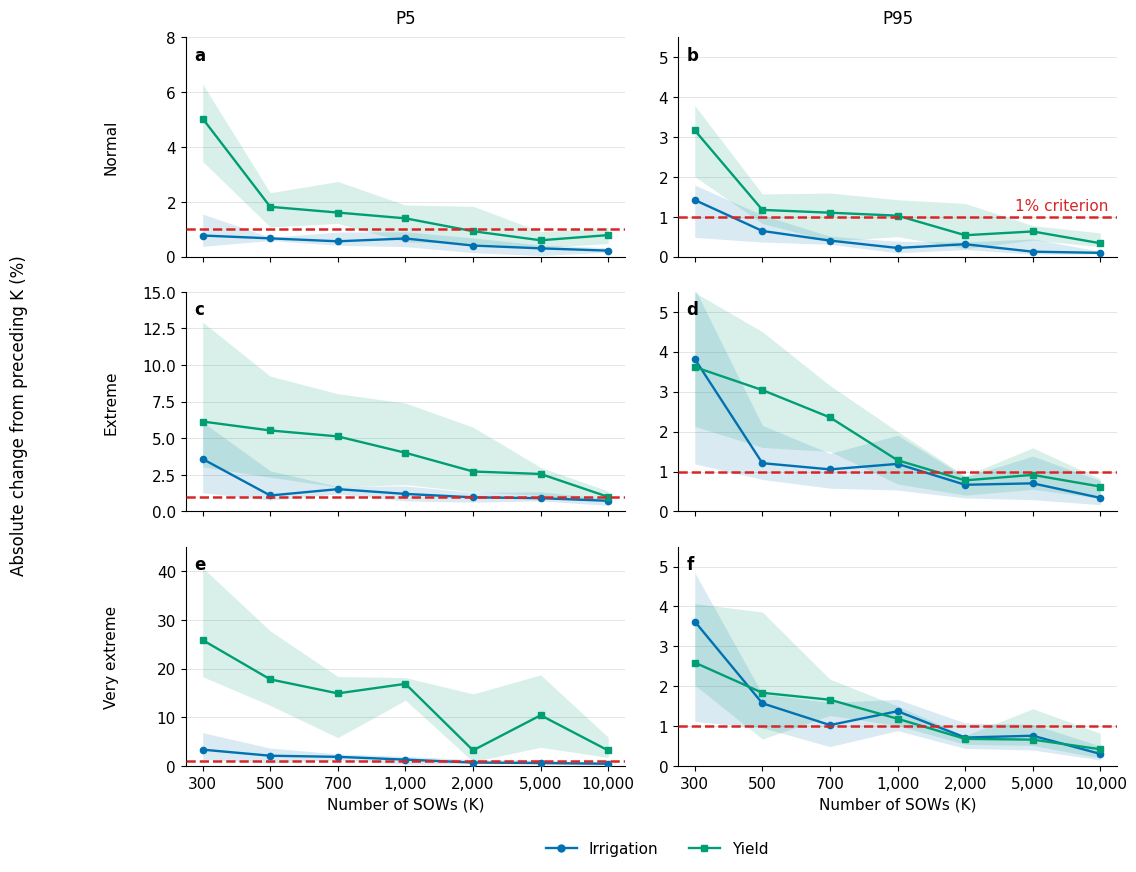

In [2]:
# Convergence Analysis of Irrigation and Yield Distribution Tails (P5/P95, K = 100–10,000)
# Figure S12

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
old_file = Path(
    "Output_convergence_Normal_Extreme_VeryExtreme_K5000_10Seeds/"
    "convergence_future_outputs_3strategies_seasonalDI_K100to5000_10seeds.csv"
)
new_file = Path(
    "Output_convergence_Normal_Extreme_VeryExtreme_K10000_10Seeds/"
    "convergence_future_outputs_3strategies_seasonalDI_K10000_10seeds.csv"
)
ACCEPTABLE_CHANGE = 1.0

df = pd.concat(
    [pd.read_csv(old_file), pd.read_csv(new_file)],
    ignore_index=True
)
quantiles = (
    df.groupby(["strategy", "K", "rep_seed"])
    .agg(
        irr_P5=("irr", lambda x: x.quantile(0.05)),
        irr_P95=("irr", lambda x: x.quantile(0.95)),
        yld_P5=("yld", lambda x: x.quantile(0.05)),
        yld_P95=("yld", lambda x: x.quantile(0.95))
    )
    .reset_index()
    .sort_values(["strategy", "rep_seed", "K"])
)
metrics = ["irr_P5", "irr_P95", "yld_P5", "yld_P95"]
for metric in metrics:
    previous = quantiles.groupby(
        ["strategy", "rep_seed"]
    )[metric].shift(1)

    quantiles[f"{metric}_pct_change"] = (
        (quantiles[metric] - previous).abs()
        / previous.abs() * 100
    )
summary_rows = []
for (strategy, K), group in quantiles.groupby(["strategy", "K"]):
    row = {"strategy": strategy, "K": K}
    for metric in metrics:
        col = f"{metric}_pct_change"
        values = group[col].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()
        row[f"{col}_median"] = values.median()
        row[f"{col}_P25"] = values.quantile(0.25)
        row[f"{col}_P75"] = values.quantile(0.75)

    summary_rows.append(row)
summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["strategy", "K"])
    .reset_index(drop=True)
)
strategies = {
    "Normal": "normal",
    "Extreme": "extreme",
    "Very extreme": "very_extreme"
}
print("\nYield P5 change: K = 100 to 300")
for label, code in strategies.items():
    value = summary.loc[
        (summary["strategy"] == code) &
        (summary["K"] == 300),
        "yld_P5_pct_change_median"
    ].iloc[0]

    print(f"{label}: {value:.2f}%")
final_rows = []
for label, code in strategies.items():
    row = summary.loc[
        (summary["strategy"] == code) &
        (summary["K"] == 10000)
    ].iloc[0]
    final_rows.append({
        "Strategy": label,
        "Irrigation P5": row["irr_P5_pct_change_median"],
        "Irrigation P95": row["irr_P95_pct_change_median"],
        "Yield P5": row["yld_P5_pct_change_median"],
        "Yield P95": row["yld_P95_pct_change_median"]
    })
final_table = pd.DataFrame(final_rows)
print("\nK = 5,000 to 10,000 tail changes")
print(final_table.round(3).to_string(index=False))
values = final_table.iloc[:, 1:].to_numpy().flatten()
print(
    f"\nMetrics below 1%: "
    f"{np.sum(values < ACCEPTABLE_CHANGE)}/12"
)
print("\nMetrics at or above 1%:")
for _, row in final_table.iterrows():
    for metric in [
        "Irrigation P5",
        "Irrigation P95",
        "Yield P5",
        "Yield P95"
    ]:
        if row[metric] >= ACCEPTABLE_CHANGE:
            print(
                f"{row['Strategy']} - {metric}: "
                f"{row[metric]:.2f}%"
            )
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8,
})
all_K = sorted(summary["K"].unique())
plot_K = all_K[1:]

x_positions = np.arange(len(plot_K))
k_to_position = {k: i for i, k in enumerate(plot_K)}
colors = {
    "Irrigation": "#0072B2",
    "Yield": "#009E73"
}
fig, axes = plt.subplots(
    3, 2,
    figsize=(11.5, 9),
    sharex=True,
    sharey=False
)
fig.subplots_adjust(
    left=0.17,
    right=0.98,
    top=0.94,
    bottom=0.13,
    hspace=0.16,
    wspace=0.12
)
panel_labels = ["a", "b", "c", "d", "e", "f"]
for i, (label, code) in enumerate(strategies.items()):
    s = summary[
        (summary["strategy"] == code) &
        (summary["K"].isin(plot_K))
    ].sort_values("K")
    x = s["K"].map(k_to_position).to_numpy()
    for j, percentile in enumerate(["P5", "P95"]):
        ax = axes[i, j]

        for objective, prefix, marker in [
            ("Irrigation", "irr", "o"),
            ("Yield", "yld", "s")
        ]:
            col = f"{prefix}_{percentile}_pct_change"

            median = s[f"{col}_median"].to_numpy(dtype=float)
            lower = s[f"{col}_P25"].to_numpy(dtype=float)
            upper = s[f"{col}_P75"].to_numpy(dtype=float)

            ax.fill_between(
                x, lower, upper,
                color=colors[objective],
                alpha=0.15,
                linewidth=0,
                zorder=1
            )
            ax.plot(
                x, median,
                color=colors[objective],
                marker=marker,
                markersize=4.5,
                linewidth=1.7,
                zorder=3
            )
        ax.axhline(
            ACCEPTABLE_CHANGE,
            color="#D62728",
            linestyle="--",
            linewidth=1.8,
            zorder=5
        )
        ax.text(
            0.02, 0.96,
            panel_labels[i * 2 + j],
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            ha="left",
            va="top"
        )
        ax.grid(
            axis="y",
            color="0.88",
            linewidth=0.6
        )
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(
            direction="out",
            length=3.5,
            labelsize=11
        )
        ax.set_xticks(x_positions)
        ax.set_xticklabels([f"{k:,}" for k in plot_K])
        ax.set_xlim(-0.25, len(plot_K) - 0.75)
        ax.minorticks_off()

axes[0, 0].set_ylim(0, 8)
axes[0, 1].set_ylim(0, 5.5)
axes[1, 0].set_ylim(0, 15)
axes[1, 1].set_ylim(0, 5.5)
axes[2, 0].set_ylim(0, 45)
axes[2, 1].set_ylim(0, 5.5)
axes[0, 0].set_title("P5", fontsize=12, pad=10)
axes[0, 1].set_title("P95", fontsize=12, pad=10)
for i, label in enumerate(strategies):
    axes[i, 0].text(
        -0.17, 0.5,
        label,
        transform=axes[i, 0].transAxes,
        rotation=90,
        ha="center",
        va="center",
        fontsize=11
    )
fig.text(
    0.025, 0.52,
    "Absolute change from preceding K (%)",
    rotation=90,
    ha="center",
    va="center",
    fontsize=12
)
for ax in axes[-1]:
    ax.set_xlabel("Number of SOWs (K)", fontsize=11)
legend_handles = [
    Line2D(
        [0], [0],
        color=colors["Irrigation"],
        marker="o",
        linewidth=1.7,
        markersize=5,
        label="Irrigation"
    ),
    Line2D(
        [0], [0],
        color=colors["Yield"],
        marker="s",
        linewidth=1.7,
        markersize=5,
        label="Yield"
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.58, 0.015),
    ncol=2,
    frameon=False,
    fontsize=11
)
axes[0, 1].text(
    0.98,
    ACCEPTABLE_CHANGE + 0.08,
    "1% criterion",
    transform=axes[0, 1].get_yaxis_transform(),
    fontsize=11,
    color="#D62728",
    ha="right",
    va="bottom"
)
plt.show()